In [1]:
import pandas as pd
import numpy as np

DATA_PATH = "../data/processed/cleaned_housing_prices.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Shape: (250000, 30)


,ID,State,City,Locality,Property_Type,BHK,Size_in_SqFt,Price_in_Lakhs,Price_per_SqFt_Original_Lakhs,Year_Built,...,Facing,Owner_Type,Availability_Status,Price_per_SqFt,Has_Pool,Has_Clubhouse,Has_Garden,Has_Gym,Has_Playground,Original_Price_per_SqFt_Was_Zero
0,1,Tamil Nadu,Chennai,Locality_84,Apartment,1,4740,489.76,0.10,1990,...,West,Owner,Ready_to_Move,10332.489451,1,1,1,1,1,0
1,2,Maharashtra,Pune,Locality_490,Independent House,3,2364,195.52,0.08,2008,...,North,Builder,Under_Construction,8270.727580,1,1,1,1,1,0
2,3,Punjab,Ludhiana,Locality_167,Apartment,2,3642,183.79,0.05,1997,...,South,Broker,Ready_to_Move,5046.403075,1,1,0,1,1,0
3,4,Rajasthan,Jodhpur,Locality_393,Independent House,2,2741,300.29,0.11,1991,...,North,Builder,Ready_to_Move,10955.490697,1,1,1,1,1,0
4,5,Rajasthan,Jaipur,Locality_466,Villa,4,4823,182.90,0.04,2002,...,East,Builder,Ready_to_Move,3792.245490,1,1,1,1,1,0


In [2]:
# Display all columns
print("Total Columns:", len(df.columns))

for index, column in enumerate(df.columns, 1):
    print(f"{index}. {column}")

print("\nDataset Information:")
df.info()

Total Columns: 30
1. ID
2. State
3. City
4. Locality
5. Property_Type
6. BHK
7. Size_in_SqFt
8. Price_in_Lakhs
9. Price_per_SqFt_Original_Lakhs
10. Year_Built
11. Furnished_Status
12. Floor_No
13. Total_Floors
14. Age_of_Property
15. Nearby_Schools
16. Nearby_Hospitals
17. Public_Transport_Accessibility
18. Parking_Space
19. Security
20. Amenities
21. Facing
22. Owner_Type
23. Availability_Status
24. Price_per_SqFt
25. Has_Pool
26. Has_Clubhouse
27. Has_Garden
28. Has_Gym
29. Has_Playground
30. Original_Price_per_SqFt_Was_Zero

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 30 columns):
 #   Column                            Non-Null Count   Dtype  
---  ------                            --------------   -----  
 0   ID                                250000 non-null  int64  
 1   State                             250000 non-null  str    
 2   City                              250000 non-null  str    
 3   Locality            

In [3]:
# ==========================================
# FEATURE ENGINEERING - PROPERTY FEATURES
# ==========================================

# 1. Property age group
df["Property_Age_Group"] = pd.cut(
    df["Age_of_Property"],
    bins=[-1, 5, 15, 30, float("inf")],
    labels=[
        "New",
        "Moderate",
        "Old",
        "Very_Old"
    ]
)

# 2. Square feet per BHK
df["SqFt_per_BHK"] = (
    df["Size_in_SqFt"] / df["BHK"]
)

# 3. BHK density per 1000 square feet
df["BHK_per_1000_SqFt"] = (
    df["BHK"] * 1000 / df["Size_in_SqFt"]
)

print("Property features created successfully!")

display(
    df[
        [
            "BHK",
            "Size_in_SqFt",
            "Age_of_Property",
            "Property_Age_Group",
            "SqFt_per_BHK",
            "BHK_per_1000_SqFt"
        ]
    ].head(10)
)

Property features created successfully!


,BHK,Size_in_SqFt,Age_of_Property,Property_Age_Group,SqFt_per_BHK,BHK_per_1000_SqFt
0,1,4740,35,Very_Old,4740.000000,0.210970
1,3,2364,17,Old,788.000000,1.269036
2,2,3642,28,Old,1821.000000,0.549149
3,2,2741,34,Very_Old,1370.500000,0.729661
4,4,4823,23,Old,1205.750000,0.829359
5,4,3500,5,New,875.000000,1.142857
6,3,4826,9,Moderate,1608.666667,0.621633
7,5,4252,4,New,850.400000,1.175917
8,4,2678,22,Old,669.500000,1.493652
9,2,1393,14,Moderate,696.500000,1.435750


In [4]:
# ==========================================
# AMENITY FEATURE ENGINEERING
# ==========================================

amenity_columns = [
    "Has_Pool",
    "Has_Clubhouse",
    "Has_Garden",
    "Has_Gym",
    "Has_Playground"
]

# Total number of available amenities
df["Total_Amenities"] = (
    df[amenity_columns].sum(axis=1)
)

print("Amenity features created successfully!")

display(
    df[
        amenity_columns + ["Total_Amenities"]
    ].head(10)
)

Amenity features created successfully!


,Has_Pool,Has_Clubhouse,Has_Garden,Has_Gym,Has_Playground,Total_Amenities
0,1,1,1,1,1,5
1,1,1,1,1,1,5
2,1,1,0,1,1,4
3,1,1,1,1,1,5
4,1,1,1,1,1,5
5,0,1,0,0,1,2
6,0,1,1,0,1,3
7,1,1,0,1,1,4
8,0,1,1,0,1,3
9,0,1,1,1,1,4


In [5]:
# ==========================================
# PRICE CATEGORY FEATURE
# ==========================================

df["Price_Category"] = pd.cut(
    df["Price_in_Lakhs"],
    bins=[
        -np.inf,
        50,
        100,
        200,
        500,
        np.inf
    ],
    labels=[
        "Budget",
        "Affordable",
        "Mid_Range",
        "Premium",
        "Luxury"
    ]
)

print("Price categories created!")

display(
    df["Price_Category"].value_counts()
)

Price categories created!


Price_Category
Premium       152483
Mid_Range      51778
Affordable     25432
Budget         20307
Luxury             0
Name: count, dtype: int64

In [6]:
# Property type distribution
display(
    df.groupby("Property_Type")
    .agg(
        Total_Properties=("ID", "count"),
        Average_Price=("Price_in_Lakhs", "mean"),
        Average_Size=("Size_in_SqFt", "mean"),
        Average_BHK=("BHK", "mean")
    )
)

,Total_Properties,Average_Price,Average_Size,Average_BHK
Property_Type,,,,
Apartment,82956,254.622116,2751.174333,3.001760
Independent House,83300,255.374150,2742.612017,3.003301
Villa,83744,253.768802,2755.627926,2.993170


In [7]:
new_features = [
    "Property_Age_Group",
    "SqFt_per_BHK",
    "BHK_per_1000_SqFt",
    "Total_Amenities",
    "Price_Category"
]

print("New Features Summary:")

display(df[new_features].head(10))

print("\nMissing values in new features:")
display(df[new_features].isnull().sum())

New Features Summary:


,Property_Age_Group,SqFt_per_BHK,BHK_per_1000_SqFt,Total_Amenities,Price_Category
0,Very_Old,4740.000000,0.210970,5,Premium
1,Old,788.000000,1.269036,5,Mid_Range
2,Old,1821.000000,0.549149,4,Mid_Range
3,Very_Old,1370.500000,0.729661,5,Premium
4,Old,1205.750000,0.829359,5,Mid_Range
5,New,875.000000,1.142857,2,Mid_Range
6,Moderate,1608.666667,0.621633,3,Premium
7,New,850.400000,1.175917,4,Mid_Range
8,Old,669.500000,1.493652,3,Mid_Range
9,Moderate,696.500000,1.435750,4,Mid_Range



Missing values in new features:


Property_Age_Group    0
SqFt_per_BHK          0
BHK_per_1000_SqFt     0
Total_Amenities       0
Price_Category        0
dtype: int64

In [8]:
# ==========================================
# FEATURE ENGINEERING VALIDATION
# ==========================================

print("Dataset Shape:", df.shape)

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum().sum())

# Check infinite values
print("\nInfinite Values:")

numeric_df = df.select_dtypes(include=np.number)

print(
    np.isinf(numeric_df).sum().sum()
)

# Check property age groups
print("\nProperty Age Groups:")
display(df["Property_Age_Group"].value_counts())

# Check amenities
print("\nTotal Amenities Distribution:")
display(df["Total_Amenities"].value_counts().sort_index())

# Check price range
print("\nProperty Price Statistics:")
display(df["Price_in_Lakhs"].describe())

# Check maximum price
print(
    "\nMaximum Property Price:",
    df["Price_in_Lakhs"].max(),
    "Lakhs"
)

Dataset Shape: (250000, 35)

Missing Values:
0

Infinite Values:
0

Property Age Groups:


Property_Age_Group
Old         110382
Moderate     73472
Very_Old     36580
New          29566
Name: count, dtype: int64


Total Amenities Distribution:


Total_Amenities
1    50106
2    49806
3    49862
4    50362
5    49864
Name: count, dtype: int64


Property Price Statistics:


count    250000.000000
mean        254.586854
std         141.349921
min          10.000000
25%         132.550000
50%         253.870000
75%         376.880000
max         500.000000
Name: Price_in_Lakhs, dtype: float64


Maximum Property Price: 500.0 Lakhs


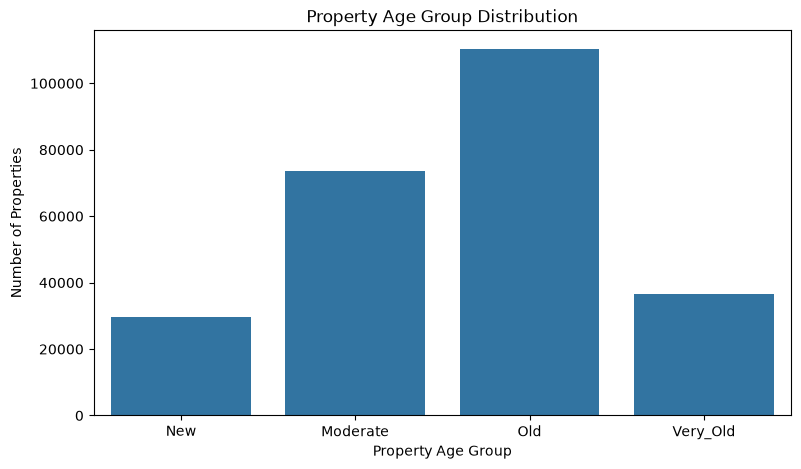

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# Property age distribution
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Property_Age_Group"
)

plt.title("Property Age Group Distribution")
plt.xlabel("Property Age Group")
plt.ylabel("Number of Properties")

plt.show()

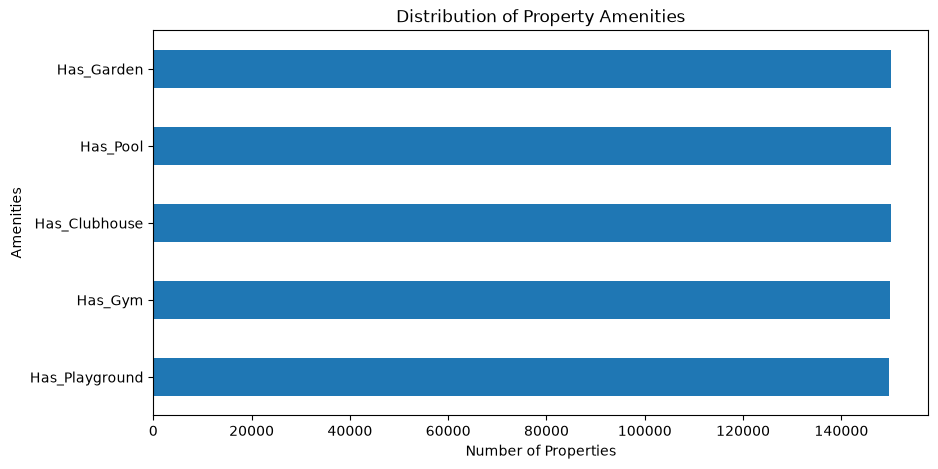

In [10]:
# Amenity distribution

plt.figure(figsize=(10, 5))

df[amenity_columns].sum().sort_values().plot(
    kind="barh"
)

plt.title("Distribution of Property Amenities")
plt.xlabel("Number of Properties")
plt.ylabel("Amenities")

plt.show()

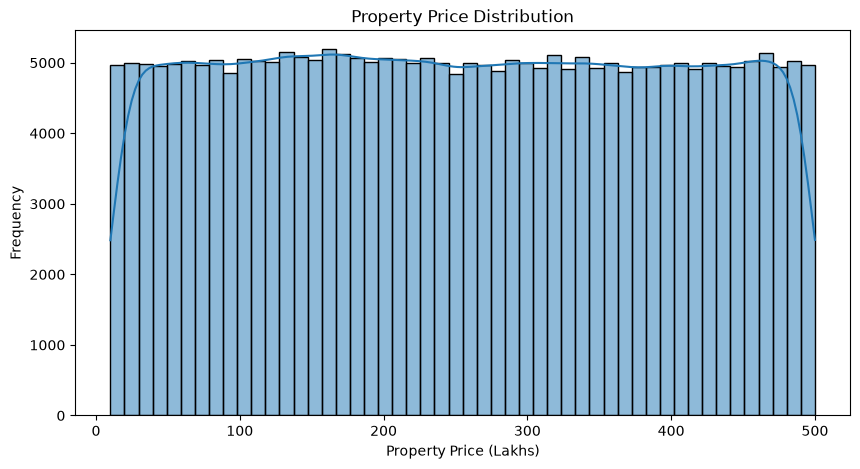

In [11]:
# Property price distribution

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Price_in_Lakhs",
    bins=50,
    kde=True
)

plt.title("Property Price Distribution")
plt.xlabel("Property Price (Lakhs)")
plt.ylabel("Frequency")

plt.show()

In [12]:
import os

OUTPUT_PATH = (
    "../data/processed/final_housing_prices.csv"
)

os.makedirs(
    "../data/processed",
    exist_ok=True
)

df.to_csv(
    OUTPUT_PATH,
    index=False
)

print("Feature engineering completed!")
print("Final Shape:", df.shape)
print("Saved:", OUTPUT_PATH)

Feature engineering completed!
Final Shape: (250000, 35)
Saved: ../data/processed/final_housing_prices.csv


In [13]:
# ==========================================
# DATA VALIDATION
# STEP 1: LOAD DATASET
# ==========================================

import pandas as pd
import numpy as np

DATA_PATH = "../data/processed/cleaned_housing_prices.csv"

df = pd.read_csv(DATA_PATH)

print("=" * 50)
print("DAY 5 - DATA VALIDATION")
print("=" * 50)

print("\nDataset Shape:")
print(df.shape)

print("\nTotal Rows:", len(df))

print("Total Columns:", len(df.columns))

print("\nFirst 5 Records:")
display(df.head())

print("\nDataset Information:")
df.info()

DAY 5 - DATA VALIDATION

Dataset Shape:
(250000, 30)

Total Rows: 250000
Total Columns: 30

First 5 Records:


,ID,State,City,Locality,Property_Type,BHK,Size_in_SqFt,Price_in_Lakhs,Price_per_SqFt_Original_Lakhs,Year_Built,...,Facing,Owner_Type,Availability_Status,Price_per_SqFt,Has_Pool,Has_Clubhouse,Has_Garden,Has_Gym,Has_Playground,Original_Price_per_SqFt_Was_Zero
0,1,Tamil Nadu,Chennai,Locality_84,Apartment,1,4740,489.76,0.10,1990,...,West,Owner,Ready_to_Move,10332.489451,1,1,1,1,1,0
1,2,Maharashtra,Pune,Locality_490,Independent House,3,2364,195.52,0.08,2008,...,North,Builder,Under_Construction,8270.727580,1,1,1,1,1,0
2,3,Punjab,Ludhiana,Locality_167,Apartment,2,3642,183.79,0.05,1997,...,South,Broker,Ready_to_Move,5046.403075,1,1,0,1,1,0
3,4,Rajasthan,Jodhpur,Locality_393,Independent House,2,2741,300.29,0.11,1991,...,North,Builder,Ready_to_Move,10955.490697,1,1,1,1,1,0
4,5,Rajasthan,Jaipur,Locality_466,Villa,4,4823,182.90,0.04,2002,...,East,Builder,Ready_to_Move,3792.245490,1,1,1,1,1,0



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 30 columns):
 #   Column                            Non-Null Count   Dtype  
---  ------                            --------------   -----  
 0   ID                                250000 non-null  int64  
 1   State                             250000 non-null  str    
 2   City                              250000 non-null  str    
 3   Locality                          250000 non-null  str    
 4   Property_Type                     250000 non-null  str    
 5   BHK                               250000 non-null  int64  
 6   Size_in_SqFt                      250000 non-null  int64  
 7   Price_in_Lakhs                    250000 non-null  float64
 8   Price_per_SqFt_Original_Lakhs     250000 non-null  float64
 9   Year_Built                        250000 non-null  int64  
 10  Furnished_Status                  250000 non-null  str    
 11  Floor_No                          250000 

In [14]:
# ==========================================
# MISSING VALUES AND DUPLICATE VALIDATION
# ==========================================

quality_report = pd.DataFrame({
    "Data_Type": df.dtypes.astype(str),
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (
        df.isnull().sum() / len(df) * 100
    ).round(2),
    "Unique_Values": df.nunique(),
    "Duplicate_Values": [
        df[col].duplicated().sum()
        for col in df.columns
    ]
})

display(
    quality_report.sort_values(
        "Missing_Count",
        ascending=False
    )
)

print("\nTotal Missing Values:",
      df.isnull().sum().sum())

print("Total Duplicate Rows:",
      df.duplicated().sum())

print("Total Duplicate IDs:",
      df["ID"].duplicated().sum())

,Data_Type,Missing_Count,Missing_Percentage,Unique_Values,Duplicate_Values
ID,int64,0,0.0,250000,0
State,str,0,0.0,20,249980
City,str,0,0.0,42,249958
Locality,str,0,0.0,500,249500
Property_Type,str,0,0.0,3,249997
BHK,int64,0,0.0,5,249995
Size_in_SqFt,int64,0,0.0,4501,245499
Price_in_Lakhs,float64,0,0.0,48700,201300
Price_per_SqFt_Original_Lakhs,float64,0,0.0,100,249900
Year_Built,int64,0,0.0,34,249966



Total Missing Values: 0
Total Duplicate Rows: 0
Total Duplicate IDs: 0


In [15]:
# ==========================================
# TARGET LEAKAGE INVESTIGATION
# ==========================================

target = "Price_in_Lakhs"

potential_leakage = [
    "Price_per_SqFt",
    "Price_Category",
    "Price_per_SqFt_Original_Lakhs",
    "Original_Price_per_SqFt_Was_Zero"
]

print("TARGET VARIABLE:", target)

print("\nPotential leakage columns:")

for col in potential_leakage:

    if col in df.columns:
        print(
            f"{col}: PRESENT | "
            f"Unique values: {df[col].nunique()}"
        )

print("\nTarget variable statistics:")

display(df[target].describe())

TARGET VARIABLE: Price_in_Lakhs

Potential leakage columns:
Price_per_SqFt: PRESENT | Unique values: 249166
Price_per_SqFt_Original_Lakhs: PRESENT | Unique values: 100
Original_Price_per_SqFt_Was_Zero: PRESENT | Unique values: 2

Target variable statistics:


count    250000.000000
mean        254.586854
std         141.349921
min          10.000000
25%         132.550000
50%         253.870000
75%         376.880000
max         500.000000
Name: Price_in_Lakhs, dtype: float64

In [16]:
# ==========================================
# PRICE FEATURE LEAKAGE VERIFICATION
# ==========================================

# Recalculate price per square foot
df["Calculated_Price_per_SqFt"] = (
    df["Price_in_Lakhs"] * 100000
    / df["Size_in_SqFt"]
)

# Compare existing and calculated values
df["Price_SqFt_Difference"] = abs(
    df["Price_per_SqFt"]
    - df["Calculated_Price_per_SqFt"]
)

print("PRICE PER SQFT VERIFICATION")

print("\nMean Difference:")
print(df["Price_SqFt_Difference"].mean())

print("\nMaximum Difference:")
print(df["Price_SqFt_Difference"].max())

print("\nPercentage of matching records:")

matching = np.isclose(
    df["Price_per_SqFt"],
    df["Calculated_Price_per_SqFt"],
    rtol=1e-5,
    atol=1e-5
)

print(matching.mean() * 100)

# Investigate original price per sqft
print("\nOriginal Price per SqFt statistics:")
display(df["Price_per_SqFt_Original_Lakhs"].describe())

print("\nCorrelation with target:")

print(
    df[
        [
            "Price_in_Lakhs",
            "Price_per_SqFt_Original_Lakhs"
        ]
    ].corr()
)

# Check zero flag consistency
print("\nZero flag distribution:")

display(
    df["Original_Price_per_SqFt_Was_Zero"].value_counts()
)

PRICE PER SQFT VERIFICATION

Mean Difference:
0.0

Maximum Difference:
0.0

Percentage of matching records:
100.0

Original Price per SqFt statistics:


count    250000.000000
mean          0.130597
std           0.130747
min           0.000000
25%           0.050000
50%           0.090000
75%           0.160000
max           0.990000
Name: Price_per_SqFt_Original_Lakhs, dtype: float64


Correlation with target:
                               Price_in_Lakhs  Price_per_SqFt_Original_Lakhs
Price_in_Lakhs                       1.000000                       0.555625
Price_per_SqFt_Original_Lakhs        0.555625                       1.000000

Zero flag distribution:


Original_Price_per_SqFt_Was_Zero
0    247466
1      2534
Name: count, dtype: int64

In [17]:
# ==========================================
# ORIGINAL PRICE FEATURE INVESTIGATION
# ==========================================

df["Implied_Price"] = (
    df["Price_per_SqFt_Original_Lakhs"]
    * df["Size_in_SqFt"]
)

df["Implied_Price_Difference"] = abs(
    df["Price_in_Lakhs"] - df["Implied_Price"]
)

print("ORIGINAL PRICE FEATURE INVESTIGATION")

print("\nImplied Price Statistics:")
display(df["Implied_Price"].describe())

print("\nDifference Statistics:")
display(df["Implied_Price_Difference"].describe())

print("\nCorrelation with Target:")

display(
    df[
        [
            "Price_in_Lakhs",
            "Price_per_SqFt_Original_Lakhs",
            "Size_in_SqFt",
            "Implied_Price"
        ]
    ].corr().round(4)
)

print("\nSample Comparison:")

display(
    df[
        [
            "Price_in_Lakhs",
            "Size_in_SqFt",
            "Price_per_SqFt_Original_Lakhs",
            "Implied_Price",
            "Implied_Price_Difference"
        ]
    ].head(15)
)

ORIGINAL PRICE FEATURE INVESTIGATION

Implied Price Statistics:


count    250000.000000
mean        254.615421
std         141.629855
min           0.000000
25%         133.420000
50%         253.260000
75%         377.200000
max         522.830000
Name: Implied_Price, dtype: float64


Difference Statistics:


count    250000.000000
mean          6.922810
std           5.486854
min           0.000000
25%           2.450000
50%           5.480000
75%          10.380000
max          24.940000
Name: Implied_Price_Difference, dtype: float64


Correlation with Target:


,Price_in_Lakhs,Price_per_SqFt_Original_Lakhs,Size_in_SqFt,Implied_Price
Price_in_Lakhs,1.0000,0.5556,-0.0025,0.9981
Price_per_SqFt_Original_Lakhs,0.5556,1.0000,-0.6145,0.5557
Size_in_SqFt,-0.0025,-0.6145,1.0000,-0.0027
Implied_Price,0.9981,0.5557,-0.0027,1.0000



Sample Comparison:


,Price_in_Lakhs,Size_in_SqFt,Price_per_SqFt_Original_Lakhs,Implied_Price,Implied_Price_Difference
0,489.76,4740,0.10,474.00,15.76
1,195.52,2364,0.08,189.12,6.40
2,183.79,3642,0.05,182.10,1.69
3,300.29,2741,0.11,301.51,1.22
4,182.90,4823,0.04,192.92,10.02
5,135.28,3500,0.04,140.00,4.72
6,318.12,4826,0.07,337.82,19.70
7,141.39,4252,0.03,127.56,13.83
8,189.16,2678,0.07,187.46,1.70
9,187.42,1393,0.13,181.09,6.33


In [18]:
# ==========================================
# LEAKAGE-SAFE FEATURE SELECTION
# ==========================================

target_column = "Price_in_Lakhs"

leakage_columns = [
    "ID",
    "Price_per_SqFt",
    "Price_per_SqFt_Original_Lakhs",
    "Original_Price_per_SqFt_Was_Zero",
    "Price_Category",
    "Calculated_Price_per_SqFt",
    "Price_SqFt_Difference",
    "Implied_Price",
    "Implied_Price_Difference"
]

# Remove only columns that exist
columns_to_remove = [
    col for col in leakage_columns
    if col in df.columns
]

# Create separate dataset
ml_df = df.drop(
    columns=columns_to_remove
).copy()

# Separate features and target
X = ml_df.drop(columns=[target_column])
y = ml_df[target_column]

print("LEAKAGE-SAFE DATASET CREATED")

print("\nOriginal Dataset Shape:", df.shape)

print("ML Dataset Shape:", ml_df.shape)

print("Feature Matrix Shape:", X.shape)

print("Target Shape:", y.shape)

print("\nRemoved Columns:")
print(columns_to_remove)

print("\nRemaining Features:")
print(X.columns.tolist())

print("\nTarget Variable:")
print(y.name)

LEAKAGE-SAFE DATASET CREATED

Original Dataset Shape: (250000, 34)
ML Dataset Shape: (250000, 26)
Feature Matrix Shape: (250000, 25)
Target Shape: (250000,)

Removed Columns:
['ID', 'Price_per_SqFt', 'Price_per_SqFt_Original_Lakhs', 'Original_Price_per_SqFt_Was_Zero', 'Calculated_Price_per_SqFt', 'Price_SqFt_Difference', 'Implied_Price', 'Implied_Price_Difference']

Remaining Features:
['State', 'City', 'Locality', 'Property_Type', 'BHK', 'Size_in_SqFt', 'Year_Built', 'Furnished_Status', 'Floor_No', 'Total_Floors', 'Age_of_Property', 'Nearby_Schools', 'Nearby_Hospitals', 'Public_Transport_Accessibility', 'Parking_Space', 'Security', 'Amenities', 'Facing', 'Owner_Type', 'Availability_Status', 'Has_Pool', 'Has_Clubhouse', 'Has_Garden', 'Has_Gym', 'Has_Playground']

Target Variable:
Price_in_Lakhs


In [19]:
# ==========================================
# FEATURE TYPE VALIDATION
# ==========================================

print("=" * 55)
print("FEATURE TYPE VALIDATION")
print("=" * 55)

# 1. Identify numerical and categorical columns

numerical_columns = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_columns = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("\nNumerical Features:", len(numerical_columns))
print(numerical_columns)

print("\nCategorical Features:", len(categorical_columns))
print(categorical_columns)


# 2. Feature data type summary

feature_summary = pd.DataFrame({
    "Feature": X.columns,
    "Data_Type": X.dtypes.astype(str).values,
    "Unique_Values": X.nunique().values,
    "Missing_Values": X.isnull().sum().values
})

display(feature_summary)


# 3. Identify binary features

binary_columns = [
    col for col in X.columns
    if X[col].nunique() == 2
]

print("\nBinary Features:")
print(binary_columns)


# 4. Identify high-cardinality categorical features

print("\nCategorical Feature Cardinality:")

cardinality = pd.DataFrame({
    "Feature": categorical_columns,
    "Unique_Values": [
        X[col].nunique()
        for col in categorical_columns
    ]
}).sort_values(
    "Unique_Values",
    ascending=False
)

display(cardinality)


# 5. Numerical feature summary

print("\nNumerical Feature Statistics:")

display(X[numerical_columns].describe().T)


# 6. Check missing values

print("\nMissing Values in X:")
print(X.isnull().sum().sum())

print("\nMissing Values in y:")
print(y.isnull().sum())


# 7. Final validation

print("\nVALIDATION SUMMARY")

print("Total Features:", X.shape[1])
print("Numerical Features:", len(numerical_columns))
print("Categorical Features:", len(categorical_columns))
print("Binary Features:", len(binary_columns))

print("\nFeature validation completed!")

FEATURE TYPE VALIDATION

Numerical Features: 15
['BHK', 'Size_in_SqFt', 'Year_Built', 'Floor_No', 'Total_Floors', 'Age_of_Property', 'Nearby_Schools', 'Nearby_Hospitals', 'Parking_Space', 'Security', 'Has_Pool', 'Has_Clubhouse', 'Has_Garden', 'Has_Gym', 'Has_Playground']

Categorical Features: 10
['State', 'City', 'Locality', 'Property_Type', 'Furnished_Status', 'Public_Transport_Accessibility', 'Amenities', 'Facing', 'Owner_Type', 'Availability_Status']


C:\Users\rahul\AppData\Local\Temp\ipykernel_25420\2278449848.py:15: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = X.select_dtypes(


,Feature,Data_Type,Unique_Values,Missing_Values
0,State,str,20,0
1,City,str,42,0
2,Locality,str,500,0
3,Property_Type,str,3,0
4,BHK,int64,5,0
5,Size_in_SqFt,int64,4501,0
6,Year_Built,int64,34,0
7,Furnished_Status,str,3,0
8,Floor_No,int64,31,0
9,Total_Floors,int64,30,0



Binary Features:
['Parking_Space', 'Security', 'Availability_Status', 'Has_Pool', 'Has_Clubhouse', 'Has_Garden', 'Has_Gym', 'Has_Playground']

Categorical Feature Cardinality:


,Feature,Unique_Values
2,Locality,500
6,Amenities,325
1,City,42
0,State,20
7,Facing,4
3,Property_Type,3
5,Public_Transport_Accessibility,3
4,Furnished_Status,3
8,Owner_Type,3
9,Availability_Status,2



Numerical Feature Statistics:


,count,mean,std,min,25%,50%,75%,max
BHK,250000.0,2.999396,1.415521,1.0,2.0,3.0,4.0,5.0
Size_in_SqFt,250000.0,2749.813216,1300.606954,500.0,1623.0,2747.0,3874.0,5000.0
Year_Built,250000.0,2006.520012,9.808575,1990.0,1998.0,2007.0,2015.0,2023.0
Floor_No,250000.0,14.966800,8.948047,0.0,7.0,15.0,23.0,30.0
Total_Floors,250000.0,15.503004,8.671618,1.0,8.0,15.0,23.0,30.0
Age_of_Property,250000.0,18.479988,9.808575,2.0,10.0,18.0,27.0,35.0
Nearby_Schools,250000.0,5.499860,2.878639,1.0,3.0,5.0,8.0,10.0
Nearby_Hospitals,250000.0,5.498016,2.871860,1.0,3.0,5.0,8.0,10.0
Parking_Space,250000.0,0.498176,0.499998,0.0,0.0,0.0,1.0,1.0
Security,250000.0,0.500932,0.500000,0.0,0.0,1.0,1.0,1.0



Missing Values in X:
0

Missing Values in y:
0

VALIDATION SUMMARY
Total Features: 25
Numerical Features: 15
Categorical Features: 10
Binary Features: 8

Feature validation completed!


In [20]:
# ==========================================
# FEATURE CONSISTENCY AND LOGICAL VALIDATION
# ==========================================

print("=" * 55)
print("FEATURE CONSISTENCY VALIDATION")
print("=" * 55)

# 1. Check relationship between Year Built and Age

df["Calculated_Age"] = 2025 - df["Year_Built"]

age_difference = (
    df["Age_of_Property"] - df["Calculated_Age"]
)

print("\n1. YEAR BUILT vs PROPERTY AGE")

print("Matching records:",
      (age_difference == 0).sum())

print("Non-matching records:",
      (age_difference != 0).sum())

print("Maximum difference:",
      age_difference.abs().max())


# 2. Validate floor numbers

invalid_floors = df[
    df["Floor_No"] > df["Total_Floors"]
]

print("\n2. FLOOR VALIDATION")

print("Invalid floor records:", len(invalid_floors))

print("Ground floor properties:",
      (df["Floor_No"] == 0).sum())


# 3. Validate BHK and property size

invalid_size = df[
    (df["BHK"] <= 0) |
    (df["Size_in_SqFt"] <= 0)
]

print("\n3. SIZE AND BHK VALIDATION")

print("Invalid records:", len(invalid_size))


# 4. Validate binary numerical features

binary_numeric = [
    "Parking_Space",
    "Security",
    "Has_Pool",
    "Has_Clubhouse",
    "Has_Garden",
    "Has_Gym",
    "Has_Playground"
]

print("\n4. BINARY FEATURE VALIDATION")

for col in binary_numeric:
    print(col, ":", sorted(df[col].unique()))


# 5. Validate State-City relationships

city_state_mapping = (
    df.groupby("City")["State"]
    .nunique()
)

print("\n5. CITY-STATE VALIDATION")

print("Cities mapped to multiple states:",
      (city_state_mapping > 1).sum())


# 6. Inspect Amenities values

print("\n6. AMENITIES INVESTIGATION")

print("Unique amenities values:",
      df["Amenities"].nunique())

display(
    df["Amenities"]
    .value_counts()
    .head(20)
)

# Inspect individual examples

display(
    df[["Amenities"]]
    .drop_duplicates()
    .head(20)
)


# 7. Final logical validation summary

print("\nVALIDATION COMPLETED")

FEATURE CONSISTENCY VALIDATION

1. YEAR BUILT vs PROPERTY AGE
Matching records: 250000
Non-matching records: 0
Maximum difference: 0

2. FLOOR VALIDATION
Invalid floor records: 116304
Ground floor properties: 8203

3. SIZE AND BHK VALIDATION
Invalid records: 0

4. BINARY FEATURE VALIDATION
Parking_Space : [np.int64(0), np.int64(1)]
Security : [np.int64(0), np.int64(1)]
Has_Pool : [np.int64(0), np.int64(1)]
Has_Clubhouse : [np.int64(0), np.int64(1)]
Has_Garden : [np.int64(0), np.int64(1)]
Has_Gym : [np.int64(0), np.int64(1)]
Has_Playground : [np.int64(0), np.int64(1)]

5. CITY-STATE VALIDATION
Cities mapped to multiple states: 0

6. AMENITIES INVESTIGATION
Unique amenities values: 325


Amenities
Pool                     10218
Clubhouse                10010
Garden                   10006
Gym                       9938
Playground                9934
Pool, Playground          2545
Gym, Pool                 2534
Garden, Clubhouse         2524
Gym, Playground           2524
Playground, Gym           2519
Clubhouse, Playground     2516
Playground, Clubhouse     2506
Garden, Gym               2504
Gym, Garden               2500
Garden, Playground        2498
Clubhouse, Garden         2497
Gym, Clubhouse            2496
Pool, Clubhouse           2495
Playground, Garden        2481
Clubhouse, Gym            2470
Name: count, dtype: int64

,Amenities
0,"Playground, Gym, Garden, Pool, Clubhouse"
1,"Playground, Clubhouse, Pool, Gym, Garden"
2,"Clubhouse, Pool, Playground, Gym"
3,"Playground, Clubhouse, Gym, Pool, Garden"
4,"Playground, Garden, Gym, Pool, Clubhouse"
5,"Playground, Clubhouse"
6,"Clubhouse, Garden, Playground"
7,"Gym, Pool, Clubhouse, Playground"
8,"Garden, Clubhouse, Playground"
9,"Clubhouse, Playground, Garden, Gym"



VALIDATION COMPLETED


In [21]:
# Verify age calculation without modifying df

base_year = (
    df["Year_Built"] + df["Age_of_Property"]
)

print("Unique reference years:", base_year.nunique())
print("Reference year values:")
print(base_year.value_counts().head())

print(
    "Age and Year Built match:",
    (base_year.nunique() == 1)
)

Unique reference years: 1
Reference year values:
2025    250000
Name: count, dtype: int64
Age and Year Built match: True


In [22]:
# ==========================================
# FLOOR DATA QUALITY INVESTIGATION
# ==========================================

invalid_floors = df[
    df["Floor_No"] > df["Total_Floors"]
].copy()

print("INVALID FLOOR ANALYSIS")

print("\nInvalid Records:", len(invalid_floors))

print(
    "Invalid Percentage:",
    round(len(invalid_floors) / len(df) * 100, 2),
    "%"
)

print("\nFloor Number Distribution:")
display(df["Floor_No"].value_counts().sort_index())

print("\nTotal Floors Distribution:")
display(df["Total_Floors"].value_counts().sort_index())

print("\nInvalid Floor Examples:")

display(
    invalid_floors[
        ["City", "Property_Type", "Floor_No", "Total_Floors"]
    ].head(20)
)

print("\nInvalid Floor Combinations:")

display(
    invalid_floors.groupby(
        ["Floor_No", "Total_Floors"]
    ).size()
    .reset_index(name="Count")
    .sort_values("Count", ascending=False)
    .head(20)
)

INVALID FLOOR ANALYSIS

Invalid Records: 116304
Invalid Percentage: 46.52 %

Floor Number Distribution:


Floor_No
0     8203
1     8076
2     8125
3     8073
4     7949
5     8174
6     8166
7     8106
8     8149
9     8064
10    7975
11    8041
12    8077
13    7990
14    8108
15    8154
16    8051
17    8197
18    8145
19    7868
20    8283
21    7991
22    7876
23    7912
24    7869
25    8056
26    8114
27    8091
28    7966
29    8075
30    8076
Name: count, dtype: int64


Total Floors Distribution:


Total_Floors
1     8347
2     8380
3     8439
4     8297
5     8501
6     8327
7     8216
8     8301
9     8416
10    8395
11    8135
12    8303
13    8271
14    8367
15    8336
16    8279
17    8251
18    8205
19    8316
20    8414
21    8158
22    8218
23    8388
24    8520
25    8354
26    8432
27    8403
28    8334
29    8212
30    8485
Name: count, dtype: int64


Invalid Floor Examples:


,City,Property_Type,Floor_No,Total_Floors
0,Chennai,Apartment,22,1
1,Pune,Independent House,21,20
4,Jaipur,Villa,3,2
5,Durgapur,Apartment,27,1
6,Coimbatore,Independent House,16,5
7,Bilaspur,Independent House,24,4
8,New Delhi,Villa,23,16
12,Nagpur,Independent House,9,1
13,New Delhi,Independent House,13,4
14,Lucknow,Apartment,26,18



Invalid Floor Combinations:


,Floor_No,Total_Floors,Count
23,8,3,317
333,27,9,316
332,27,8,313
109,16,5,307
0,2,1,306
12,6,3,304
33,9,6,304
82,14,5,303
132,17,13,302
11,6,2,300


In [23]:
# ==========================================
# AMENITIES FEATURE ENGINEERING
# ==========================================

amenity_list = [
    "Pool",
    "Clubhouse",
    "Garden",
    "Gym",
    "Playground"
]

# Normalize text
amenities_clean = (
    X["Amenities"]
    .fillna("")
    .str.lower()
)

# Create independent binary features
for amenity in amenity_list:

    column_name = f"Amenity_{amenity}"

    X[column_name] = amenities_clean.apply(
        lambda values: int(
            amenity.lower() in [
                item.strip()
                for item in values.split(",")
            ]
        )
    )

print("AMENITIES ENCODING COMPLETED")

amenity_features = [
    f"Amenity_{amenity}"
    for amenity in amenity_list
]

display(
    X[["Amenities"] + amenity_features].head(15)
)

print("\nAmenity Distribution:")

display(
    X[amenity_features].sum()
)

AMENITIES ENCODING COMPLETED


,Amenities,Amenity_Pool,Amenity_Clubhouse,Amenity_Garden,Amenity_Gym,Amenity_Playground
0,"Playground, Gym, Garden, Pool, Clubhouse",1,1,1,1,1
1,"Playground, Clubhouse, Pool, Gym, Garden",1,1,1,1,1
2,"Clubhouse, Pool, Playground, Gym",1,1,0,1,1
3,"Playground, Clubhouse, Gym, Pool, Garden",1,1,1,1,1
4,"Playground, Garden, Gym, Pool, Clubhouse",1,1,1,1,1
5,"Playground, Clubhouse",0,1,0,0,1
6,"Clubhouse, Garden, Playground",0,1,1,0,1
7,"Gym, Pool, Clubhouse, Playground",1,1,0,1,1
8,"Garden, Clubhouse, Playground",0,1,1,0,1
9,"Clubhouse, Playground, Garden, Gym",0,1,1,1,1



Amenity Distribution:


Amenity_Pool          150096
Amenity_Clubhouse     150059
Amenity_Garden        150177
Amenity_Gym           149960
Amenity_Playground    149780
dtype: int64

In [24]:
# ==========================================
# AMENITY CONSISTENCY CHECK
# ==========================================

comparison = {
    "Pool": "Has_Pool",
    "Clubhouse": "Has_Clubhouse",
    "Garden": "Has_Garden",
    "Gym": "Has_Gym",
    "Playground": "Has_Playground"
}

print("AMENITY CONSISTENCY REPORT")

for amenity, existing_column in comparison.items():

    new_column = f"Amenity_{amenity}"

    mismatches = (
        X[new_column] != X[existing_column]
    ).sum()

    print(
        f"{amenity}: "
        f"{mismatches} mismatches"
    )

AMENITY CONSISTENCY REPORT
Pool: 0 mismatches
Clubhouse: 0 mismatches
Garden: 0 mismatches
Gym: 0 mismatches
Playground: 0 mismatches


In [25]:
# ==========================================
# REMOVE REDUNDANT AMENITY FEATURES
# ==========================================

redundant_amenity_columns = [
    "Amenities",
    "Amenity_Pool",
    "Amenity_Clubhouse",
    "Amenity_Garden",
    "Amenity_Gym",
    "Amenity_Playground"
]

X = X.drop(
    columns=[
        col for col in redundant_amenity_columns
        if col in X.columns
    ]
)

print("Redundant amenity columns removed.")

print("\nRemaining amenity features:")

display(
    X[
        [
            "Has_Pool",
            "Has_Clubhouse",
            "Has_Garden",
            "Has_Gym",
            "Has_Playground"
        ]
    ].head()
)

print("\nUpdated feature shape:", X.shape)

Redundant amenity columns removed.

Remaining amenity features:


,Has_Pool,Has_Clubhouse,Has_Garden,Has_Gym,Has_Playground
0,1,1,1,1,1
1,1,1,1,1,1
2,1,1,0,1,1
3,1,1,1,1,1
4,1,1,1,1,1



Updated feature shape: (250000, 24)


In [26]:
# ==========================================
# FLOOR VALIDATION BY PROPERTY TYPE
# ==========================================

df["Floor_Status"] = np.where(
    df["Floor_No"] <= df["Total_Floors"],
    "Valid",
    "Invalid"
)

floor_analysis = (
    df.groupby(["Property_Type", "Floor_Status"])
    .size()
    .unstack(fill_value=0)
)

floor_analysis["Invalid_Percentage"] = (
    floor_analysis["Invalid"] /
    (floor_analysis["Valid"] + floor_analysis["Invalid"])
    * 100
)

display(floor_analysis.round(2))

print("\nFloor Difference Distribution:")

df["Floor_Difference"] = (
    df["Floor_No"] - df["Total_Floors"]
)

display(
    df.loc[
        df["Floor_Difference"] > 0,
        "Floor_Difference"
    ].describe()
)

print("\nValid Floor Records:", (df["Floor_Status"] == "Valid").sum())

print("Invalid Floor Records:", (df["Floor_Status"] == "Invalid").sum())

Floor_Status,Invalid,Valid,Invalid_Percentage
Property_Type,,,
Apartment,38639,44317,46.58
Independent House,38655,44645,46.40
Villa,39010,44734,46.58



Floor Difference Distribution:


count    116304.000000
mean         10.362765
std           6.943254
min           1.000000
25%           4.000000
50%           9.000000
75%          15.000000
max          29.000000
Name: Floor_Difference, dtype: float64


Valid Floor Records: 133696
Invalid Floor Records: 116304


In [27]:
# ==========================================
# REMOVE UNRELIABLE FLOOR FEATURES
# ==========================================

floor_columns = [
    "Floor_No",
    "Total_Floors"
]

X = X.drop(
    columns=[
        col for col in floor_columns
        if col in X.columns
    ]
)

print("Unreliable floor features removed.")

print("\nRemaining features:")
print(X.columns.tolist())

print("\nUpdated feature matrix:", X.shape)

print("\nDataset rows retained:", len(X))

Unreliable floor features removed.

Remaining features:
['State', 'City', 'Locality', 'Property_Type', 'BHK', 'Size_in_SqFt', 'Year_Built', 'Furnished_Status', 'Age_of_Property', 'Nearby_Schools', 'Nearby_Hospitals', 'Public_Transport_Accessibility', 'Parking_Space', 'Security', 'Facing', 'Owner_Type', 'Availability_Status', 'Has_Pool', 'Has_Clubhouse', 'Has_Garden', 'Has_Gym', 'Has_Playground']

Updated feature matrix: (250000, 22)

Dataset rows retained: 250000


In [28]:
# ==========================================
# REMOVE REDUNDANT AGE FEATURE
# ==========================================

if "Age_of_Property" in X.columns:
    X = X.drop(columns=["Age_of_Property"])

print("Age_of_Property removed.")
print("Year_Built retained.")

print("\nFinal feature matrix shape:", X.shape)

Age_of_Property removed.
Year_Built retained.

Final feature matrix shape: (250000, 21)


In [29]:
print("FINAL ML DATASET VALIDATION")

print("\nFeature Matrix Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nNumerical Features:")
print(X.select_dtypes(include="number").columns.tolist())

print("\nCategorical Features:")
print(X.select_dtypes(include=["object", "str"]).columns.tolist())

print("\nMissing Values:", X.isnull().sum().sum())

print("\nTarget Missing Values:", y.isnull().sum())

print("\nDuplicate Rows:", X.duplicated().sum())

FINAL ML DATASET VALIDATION

Feature Matrix Shape: (250000, 21)
Target Shape: (250000,)

Numerical Features:
['BHK', 'Size_in_SqFt', 'Year_Built', 'Nearby_Schools', 'Nearby_Hospitals', 'Parking_Space', 'Security', 'Has_Pool', 'Has_Clubhouse', 'Has_Garden', 'Has_Gym', 'Has_Playground']

Categorical Features:
['State', 'City', 'Locality', 'Property_Type', 'Furnished_Status', 'Public_Transport_Accessibility', 'Facing', 'Owner_Type', 'Availability_Status']

Missing Values: 0

Target Missing Values: 0

Duplicate Rows: 0


In [30]:
print("Numerical:", len(
    X.select_dtypes(include="number").columns
))

print("Categorical:", len(
    X.select_dtypes(include=["object", "str"]).columns
))

Numerical: 12
Categorical: 9


In [31]:
# ==========================================
# STEP 1: TRAIN TEST SPLIT
# ==========================================

from sklearn.model_selection import train_test_split

# Verify feature and target alignment
assert X.index.equals(y.index), (
    "Feature and target indexes do not match!"
)

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Display dataset information
print("=" * 50)
print("TRAIN-TEST SPLIT COMPLETED")
print("=" * 50)

print("\nOriginal Dataset:", X.shape)

print("\nTraining Dataset:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nTesting Dataset:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

print("\nTraining Percentage:",
      round(len(X_train) / len(X) * 100, 2), "%")

print("Testing Percentage:",
      round(len(X_test) / len(X) * 100, 2), "%")

# Verify missing values
print("\nMissing Values:")
print("X_train:", X_train.isnull().sum().sum())
print("X_test:", X_test.isnull().sum().sum())
print("y_train:", y_train.isnull().sum())
print("y_test:", y_test.isnull().sum())

print("\nTrain-Test Split Validation Completed!")

TRAIN-TEST SPLIT COMPLETED

Original Dataset: (250000, 21)

Training Dataset:
X_train: (200000, 21)
y_train: (200000,)

Testing Dataset:
X_test: (50000, 21)
y_test: (50000,)

Training Percentage: 80.0 %
Testing Percentage: 20.0 %

Missing Values:
X_train: 0
X_test: 0
y_train: 0
y_test: 0

Train-Test Split Validation Completed!


In [32]:
# ==========================================
# STEP 2: FEATURE IDENTIFICATION
# ==========================================

numerical_features = (
    X_train.select_dtypes(include=["number"])
    .columns.tolist()
)

categorical_features = (
    X_train.select_dtypes(
        include=["object", "str", "category"]
    )
    .columns.tolist()
)

print("NUMERICAL FEATURES:", len(numerical_features))
print(numerical_features)

print("\nCATEGORICAL FEATURES:", len(categorical_features))
print(categorical_features)

print("\nTotal Features:",
      len(numerical_features) + len(categorical_features))

NUMERICAL FEATURES: 12
['BHK', 'Size_in_SqFt', 'Year_Built', 'Nearby_Schools', 'Nearby_Hospitals', 'Parking_Space', 'Security', 'Has_Pool', 'Has_Clubhouse', 'Has_Garden', 'Has_Gym', 'Has_Playground']

CATEGORICAL FEATURES: 9
['State', 'City', 'Locality', 'Property_Type', 'Furnished_Status', 'Public_Transport_Accessibility', 'Facing', 'Owner_Type', 'Availability_Status']

Total Features: 21


In [33]:
# ==========================================
# STEP 3: PREPROCESSING IMPORTS
# ==========================================

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

print("Preprocessing libraries imported successfully.")

Preprocessing libraries imported successfully.


In [34]:
# ==========================================
# NUMERICAL TRANSFORMATION
# ==========================================

numerical_transformer = Pipeline(
    steps=[
        ("scaler", StandardScaler())
    ]
)

print("Numerical transformer created.")

Numerical transformer created.


In [35]:
# ==========================================
# CATEGORICAL TRANSFORMATION
# ==========================================

categorical_transformer = Pipeline(
    steps=[
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=True
            )
        )
    ]
)

print("Categorical transformer created.")

Categorical transformer created.


In [36]:
# ==========================================
# COMBINE PREPROCESSING TRANSFORMERS
# ==========================================

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerical",
            numerical_transformer,
            numerical_features
        ),
        (
            "categorical",
            categorical_transformer,
            categorical_features
        )
    ],
    remainder="drop"
)

print("ColumnTransformer created successfully.")

ColumnTransformer created successfully.


In [37]:
print("PREPROCESSING CONFIGURATION")

print("\nNumerical Transformer:")
print(numerical_transformer)

print("\nCategorical Transformer:")
print(categorical_transformer)

print("\nCombined Preprocessor:")
print(preprocessor)

PREPROCESSING CONFIGURATION

Numerical Transformer:
Pipeline(steps=[('scaler', StandardScaler())])

Categorical Transformer:
Pipeline(steps=[('onehot', OneHotEncoder(handle_unknown='ignore'))])

Combined Preprocessor:
ColumnTransformer(transformers=[('numerical',
                                 Pipeline(steps=[('scaler', StandardScaler())]),
                                 ['BHK', 'Size_in_SqFt', 'Year_Built',
                                  'Nearby_Schools', 'Nearby_Hospitals',
                                  'Parking_Space', 'Security', 'Has_Pool',
                                  'Has_Clubhouse', 'Has_Garden', 'Has_Gym',
                                  'Has_Playground']),
                                ('categorical',
                                 Pipeline(steps=[('onehot',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['State', 'City', 'Locality', 'Property_Type',
                          

In [38]:
# ==========================================
# STEP 4: FIT PREPROCESSOR ON TRAIN DATA
# ==========================================

X_train_processed = preprocessor.fit_transform(X_train)

print("Training preprocessing completed.")
print("Training shape:", X_train_processed.shape)

Training preprocessing completed.
Training shape: (200000, 592)


In [39]:
# ==========================================
# TRANSFORM TEST DATA
# ==========================================

X_test_processed = preprocessor.transform(X_test)

print("Testing preprocessing completed.")
print("Testing shape:", X_test_processed.shape)

Testing preprocessing completed.
Testing shape: (50000, 592)


In [40]:
# ==========================================
# PREPROCESSING VALIDATION
# ==========================================

print("=" * 50)
print("PREPROCESSING VALIDATION")
print("=" * 50)

print("\nOriginal Training Shape:", X_train.shape)
print("Processed Training Shape:", X_train_processed.shape)

print("\nOriginal Testing Shape:", X_test.shape)
print("Processed Testing Shape:", X_test_processed.shape)

print("\nData Type:")
print(type(X_train_processed))

print("\nMissing Values:")

print(
    "Training:",
    np.isnan(X_train_processed.data).sum()
    if hasattr(X_train_processed, "data")
    else np.isnan(X_train_processed).sum()
)

print(
    "Testing:",
    np.isnan(X_test_processed.data).sum()
    if hasattr(X_test_processed, "data")
    else np.isnan(X_test_processed).sum()
)

PREPROCESSING VALIDATION

Original Training Shape: (200000, 21)
Processed Training Shape: (200000, 592)

Original Testing Shape: (50000, 21)
Processed Testing Shape: (50000, 592)

Data Type:
<class 'scipy.sparse._csr.csr_matrix'>

Missing Values:
Training: 0
Testing: 0


In [41]:
# ==========================================
# ENCODED FEATURE INVESTIGATION
# ==========================================

feature_names = preprocessor.get_feature_names_out()

print("Total Encoded Features:", len(feature_names))

print("\nFirst 30 Encoded Features:")

display(
    pd.DataFrame({
        "Feature_Name": feature_names[:30]
    })
)

Total Encoded Features: 592

First 30 Encoded Features:


,Feature_Name
0,numerical__BHK
1,numerical__Size_in_SqFt
2,numerical__Year_Built
3,numerical__Nearby_Schools
4,numerical__Nearby_Hospitals
5,numerical__Parking_Space
6,numerical__Security
7,numerical__Has_Pool
8,numerical__Has_Clubhouse
9,numerical__Has_Garden


In [42]:
# ==========================================
# STEP 5.1: NUMERICAL SCALING VALIDATION
# ==========================================

numerical_train = (
    preprocessor
    .named_transformers_["numerical"]
    .transform(X_train[numerical_features])
)

scaling_report = pd.DataFrame({
    "Feature": numerical_features,
    "Mean": numerical_train.mean(axis=0),
    "Standard_Deviation": numerical_train.std(axis=0)
})

print("NUMERICAL SCALING VALIDATION")

display(scaling_report.round(4))

NUMERICAL SCALING VALIDATION


,Feature,Mean,Standard_Deviation
0,BHK,-0.0,1.0
1,Size_in_SqFt,-0.0,1.0
2,Year_Built,-0.0,1.0
3,Nearby_Schools,0.0,1.0
4,Nearby_Hospitals,0.0,1.0
5,Parking_Space,0.0,1.0
6,Security,-0.0,1.0
7,Has_Pool,0.0,1.0
8,Has_Clubhouse,-0.0,1.0
9,Has_Garden,-0.0,1.0


In [43]:
# ==========================================
# STEP 5.2: ONE-HOT ENCODING VALIDATION
# ==========================================

categorical_train = (
    preprocessor
    .named_transformers_["categorical"]
    .transform(X_train[categorical_features])
)

print("CATEGORICAL ENCODING VALIDATION")

print("Encoded categorical shape:",
      categorical_train.shape)

print("Expected active values per row:",
      len(categorical_features))

print("Minimum active values:",
      categorical_train.sum(axis=1).min())

print("Maximum active values:",
      categorical_train.sum(axis=1).max())

CATEGORICAL ENCODING VALIDATION
Encoded categorical shape: (200000, 580)
Expected active values per row: 9
Minimum active values: 9.0
Maximum active values: 9.0


In [44]:
# ==========================================
# STEP 5.3: FINAL DATASET VALIDATION
# ==========================================

from scipy.sparse import issparse
from sklearn.utils.validation import check_is_fitted

check_is_fitted(preprocessor)

print("FINAL DATASET VALIDATION")

print("\nTraining:")
print("Shape:", X_train_processed.shape)
print("Sparse:", issparse(X_train_processed))
print("Finite values:",
      np.isfinite(X_train_processed.data).all())

print("\nTesting:")
print("Shape:", X_test_processed.shape)
print("Sparse:", issparse(X_test_processed))
print("Finite values:",
      np.isfinite(X_test_processed.data).all())

print("\nTarget validation:")
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

print("\nPreprocessing validation completed.")

FINAL DATASET VALIDATION

Training:
Shape: (200000, 592)
Sparse: True
Finite values: True

Testing:
Shape: (50000, 592)
Sparse: True
Finite values: True

Target validation:
Training target: (200000,)
Testing target: (50000,)

Preprocessing validation completed.


In [45]:

# ==========================================
# REGRESSION MODEL DEVELOPMENT
# STEP 1: IMPORT LIBRARIES
# ==========================================

import pandas as pd
import numpy as np

# Regression models
from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    Lasso
)

from sklearn.tree import DecisionTreeRegressor

from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor
)

# Evaluation metrics
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Model utilities
from sklearn.base import clone
import time

print("Regression libraries imported successfully.")

print("\nAvailable Regression Models:")

models = {
    "Linear Regression": LinearRegression(),

    "Ridge Regression": Ridge(alpha=1.0),

    "Lasso Regression": Lasso(alpha=0.1),

    "Decision Tree": DecisionTreeRegressor(
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    )
}

for name in models:
    print("-", name)

print("\nTotal Models:", len(models))


Regression libraries imported successfully.

Available Regression Models:
- Linear Regression
- Ridge Regression
- Lasso Regression
- Decision Tree
- Random Forest
- Extra Trees
- Gradient Boosting

Total Models: 7


In [46]:

# ==========================================
# STEP 2: TRAINING DATA VERIFICATION
# ==========================================

print("TRAINING DATA VERIFICATION")

print("\nTraining features:", X_train_processed.shape)
print("Testing features:", X_test_processed.shape)

print("\nTraining target:", y_train.shape)
print("Testing target:", y_test.shape)

print("\nTarget data type:", y_train.dtype)

assert X_train_processed.shape[0] == len(y_train)
assert X_test_processed.shape[0] == len(y_test)

assert X_train_processed.shape[1] == X_test_processed.shape[1]

assert np.isfinite(X_train_processed.data).all()
assert np.isfinite(X_test_processed.data).all()

print("\nAll training data checks passed.")


TRAINING DATA VERIFICATION

Training features: (200000, 592)
Testing features: (50000, 592)

Training target: (200000,)
Testing target: (50000,)

Target data type: float64

All training data checks passed.


In [47]:

# ==========================================
# STEP 3: LINEAR REGRESSION BASELINE
# ==========================================

from sklearn.linear_model import LinearRegression
import time

# Initialize model
linear_model = LinearRegression()

# Start training timer
start_time = time.time()

# Train model
linear_model.fit(
    X_train_processed,
    y_train
)

training_time = time.time() - start_time

print("=" * 50)
print("LINEAR REGRESSION TRAINING COMPLETED")
print("=" * 50)

print("\nTraining Time:",
      round(training_time, 2), "seconds")

print("Model Intercept:",
      linear_model.intercept_)

print("Number of Coefficients:",
      len(linear_model.coef_))


LINEAR REGRESSION TRAINING COMPLETED

Training Time: 0.79 seconds
Model Intercept: 254.57221496658244
Number of Coefficients: 592


In [48]:

# ==========================================
# STEP 3.2: LINEAR REGRESSION PREDICTIONS
# ==========================================

# Training predictions
y_train_pred = linear_model.predict(
    X_train_processed
)

# Testing predictions
y_test_pred = linear_model.predict(
    X_test_processed
)

print("PREDICTIONS GENERATED")

print("\nActual Prices:")
print(y_test.iloc[:10].values)

print("\nPredicted Prices:")
print(np.round(y_test_pred[:10], 2))


PREDICTIONS GENERATED

Actual Prices:
[256.62  86.04 237.86 339.41 124.99  35.17 275.75 374.76 476.35 208.  ]

Predicted Prices:
[244.34 250.68 256.73 247.37 247.47 246.45 241.69 255.21 271.18 250.08]


In [49]:

# ==========================================
# STEP 3.3: MODEL EVALUATION
# ==========================================

def evaluate_regression(y_actual, y_pred):

    mae = mean_absolute_error(
        y_actual, y_pred
    )

    mse = mean_squared_error(
        y_actual, y_pred
    )

    rmse = np.sqrt(mse)

    r2 = r2_score(
        y_actual, y_pred
    )

    return {
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2_Score": r2
    }


# Evaluate training performance
train_results = evaluate_regression(
    y_train,
    y_train_pred
)

# Evaluate testing performance
test_results = evaluate_regression(
    y_test,
    y_test_pred
)

# Create comparison table
linear_results = pd.DataFrame([
    {
        "Dataset": "Training",
        **train_results
    },
    {
        "Dataset": "Testing",
        **test_results
    }
])

print("LINEAR REGRESSION PERFORMANCE")

display(linear_results.round(4))


LINEAR REGRESSION PERFORMANCE


,Dataset,MAE,MSE,RMSE,R2_Score
0,Training,122.2446,19935.1182,141.1918,0.0028
1,Testing,122.3571,19979.8541,141.3501,-0.0022


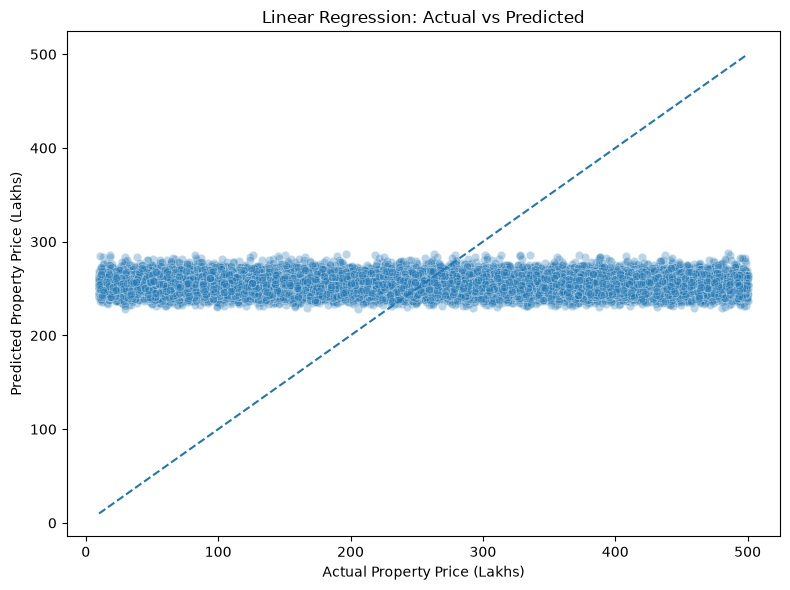

In [50]:

# ==========================================
# STEP 3.4: ACTUAL VS PREDICTED
# ==========================================

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=y_test,
    y=y_test_pred,
    alpha=0.3
)

# Perfect prediction reference line
min_price = min(y_test.min(), y_test_pred.min())
max_price = max(y_test.max(), y_test_pred.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--"
)

plt.title("Linear Regression: Actual vs Predicted")
plt.xlabel("Actual Property Price (Lakhs)")
plt.ylabel("Predicted Property Price (Lakhs)")

plt.tight_layout()
plt.show()


In [51]:

# ==========================================
# STEP 4: DUMMY REGRESSION BASELINE
# ==========================================

from sklearn.dummy import DummyRegressor

# Initialize baseline model
dummy_model = DummyRegressor(
    strategy="mean"
)

# Train baseline
start_time = time.time()

dummy_model.fit(
    X_train_processed,
    y_train
)

dummy_training_time = time.time() - start_time

# Generate predictions
dummy_train_pred = dummy_model.predict(
    X_train_processed
)

dummy_test_pred = dummy_model.predict(
    X_test_processed
)

# Evaluate performance
dummy_train_results = evaluate_regression(
    y_train,
    dummy_train_pred
)

dummy_test_results = evaluate_regression(
    y_test,
    dummy_test_pred
)

# Create comparison
baseline_comparison = pd.DataFrame([
    {
        "Model": "Dummy Regressor",
        **dummy_test_results
    },
    {
        "Model": "Linear Regression",
        **test_results
    }
])

print("BASELINE MODEL COMPARISON")

display(
    baseline_comparison.round(4)
)

print("\nDummy Prediction Value:",
      round(dummy_model.constant_[0][0], 4))

print("\nTraining Time:",
      round(dummy_training_time, 4), "seconds")


BASELINE MODEL COMPARISON


,Model,MAE,MSE,RMSE,R2_Score
0,Dummy Regressor,122.3178,19935.5310,141.1932,-0.0000
1,Linear Regression,122.3571,19979.8541,141.3501,-0.0022



Dummy Prediction Value: 254.5549

Training Time: 0.0305 seconds


In [52]:

# ==========================================
# STEP 5: RIDGE REGRESSION
# ==========================================

from sklearn.linear_model import Ridge
import time

# Initialize model
ridge_model = Ridge(
    alpha=1.0
)

# Train model
start_time = time.time()

ridge_model.fit(
    X_train_processed,
    y_train
)

ridge_training_time = time.time() - start_time

# Generate predictions
ridge_train_pred = ridge_model.predict(
    X_train_processed
)

ridge_test_pred = ridge_model.predict(
    X_test_processed
)

# Evaluate training performance
ridge_train_results = evaluate_regression(
    y_train,
    ridge_train_pred
)

# Evaluate testing performance
ridge_test_results = evaluate_regression(
    y_test,
    ridge_test_pred
)

# Performance comparison
ridge_results = pd.DataFrame([
    {
        "Model": "Dummy Regressor",
        **dummy_test_results
    },
    {
        "Model": "Linear Regression",
        **test_results
    },
    {
        "Model": "Ridge Regression",
        **ridge_test_results
    }
])

print("=" * 55)
print("RIDGE REGRESSION PERFORMANCE")
print("=" * 55)

display(ridge_results.round(4))

print("\nTraining Time:",
      round(ridge_training_time, 4), "seconds")

print("\nRidge Intercept:",
      ridge_model.intercept_)

print("\nNumber of Coefficients:",
      len(ridge_model.coef_))


RIDGE REGRESSION PERFORMANCE


,Model,MAE,MSE,RMSE,R2_Score
0,Dummy Regressor,122.3178,19935.5310,141.1932,-0.0000
1,Linear Regression,122.3571,19979.8541,141.3501,-0.0022
2,Ridge Regression,122.3568,19979.6215,141.3493,-0.0022



Training Time: 0.8516 seconds

Ridge Intercept: 254.57224095412835

Number of Coefficients: 592


In [53]:

# ==========================================
# STEP 6: LASSO REGRESSION
# ==========================================

from sklearn.linear_model import Lasso
import time

# Initialize model
lasso_model = Lasso(
    alpha=0.1,
    max_iter=5000
)

# Train model
start_time = time.time()

lasso_model.fit(
    X_train_processed,
    y_train
)

lasso_training_time = time.time() - start_time

# Generate predictions
lasso_train_pred = lasso_model.predict(
    X_train_processed
)

lasso_test_pred = lasso_model.predict(
    X_test_processed
)

# Evaluate training performance
lasso_train_results = evaluate_regression(
    y_train,
    lasso_train_pred
)

# Evaluate testing performance
lasso_test_results = evaluate_regression(
    y_test,
    lasso_test_pred
)

# Count selected features
non_zero_features = np.sum(
    lasso_model.coef_ != 0
)

zero_features = np.sum(
    lasso_model.coef_ == 0
)

# Performance comparison
lasso_results = pd.DataFrame([
    {
        "Model": "Dummy Regressor",
        **dummy_test_results
    },
    {
        "Model": "Linear Regression",
        **test_results
    },
    {
        "Model": "Ridge Regression",
        **ridge_test_results
    },
    {
        "Model": "Lasso Regression",
        **lasso_test_results
    }
])

print("=" * 55)
print("LASSO REGRESSION PERFORMANCE")
print("=" * 55)

display(lasso_results.round(4))

print("\nTraining Time:",
      round(lasso_training_time, 4), "seconds")

print("\nTotal Features:",
      len(lasso_model.coef_))

print("Non-Zero Coefficients:",
      non_zero_features)

print("Zero Coefficients:",
      zero_features)

print("Features Eliminated:",
      round(
          zero_features / len(lasso_model.coef_) * 100,
          2
      ), "%")


LASSO REGRESSION PERFORMANCE


,Model,MAE,MSE,RMSE,R2_Score
0,Dummy Regressor,122.3178,19935.5310,141.1932,-0.0000
1,Linear Regression,122.3571,19979.8541,141.3501,-0.0022
2,Ridge Regression,122.3568,19979.6215,141.3493,-0.0022
3,Lasso Regression,122.3162,19935.0620,141.1916,0.0000



Training Time: 0.66 seconds

Total Features: 592
Non-Zero Coefficients: 25
Zero Coefficients: 567
Features Eliminated: 95.78 %


In [54]:

# ==========================================
# STEP 7: DECISION TREE REGRESSION
# ==========================================

from sklearn.tree import DecisionTreeRegressor
import time

# Initialize model
decision_tree_model = DecisionTreeRegressor(
    max_depth=12,
    min_samples_split=20,
    min_samples_leaf=10,
    random_state=42
)

# Train model
start_time = time.time()

decision_tree_model.fit(
    X_train_processed,
    y_train
)

decision_tree_training_time = time.time() - start_time

# Generate predictions
dt_train_pred = decision_tree_model.predict(
    X_train_processed
)

dt_test_pred = decision_tree_model.predict(
    X_test_processed
)

# Evaluate training performance
dt_train_results = evaluate_regression(
    y_train,
    dt_train_pred
)

# Evaluate testing performance
dt_test_results = evaluate_regression(
    y_test,
    dt_test_pred
)

# Compare performance
decision_tree_results = pd.DataFrame([
    {
        "Model": "Dummy Regressor",
        **dummy_test_results
    },
    {
        "Model": "Linear Regression",
        **test_results
    },
    {
        "Model": "Ridge Regression",
        **ridge_test_results
    },
    {
        "Model": "Lasso Regression",
        **lasso_test_results
    },
    {
        "Model": "Decision Tree",
        **dt_test_results
    }
])

print("=" * 60)
print("DECISION TREE REGRESSION PERFORMANCE")
print("=" * 60)

display(
    decision_tree_results.round(4)
)

print("\nTraining Time:",
      round(decision_tree_training_time, 4),
      "seconds")

print("\nTree Depth:",
      decision_tree_model.get_depth())

print("\nNumber of Leaves:",
      decision_tree_model.get_n_leaves())

print("\nNumber of Features:",
      decision_tree_model.n_features_in_)


DECISION TREE REGRESSION PERFORMANCE


,Model,MAE,MSE,RMSE,R2_Score
0,Dummy Regressor,122.3178,19935.5310,141.1932,-0.0000
1,Linear Regression,122.3571,19979.8541,141.3501,-0.0022
2,Ridge Regression,122.3568,19979.6215,141.3493,-0.0022
3,Lasso Regression,122.3162,19935.0620,141.1916,0.0000
4,Decision Tree,122.5316,20028.5423,141.5222,-0.0047



Training Time: 3.3491 seconds

Tree Depth: 12

Number of Leaves: 182

Number of Features: 592


TARGET VARIABLE INVESTIGATION

1. TARGET STATISTICS


,Training Target
count,200000.000000
mean,254.554916
std,141.389069
min,10.000000
25%,132.460000
50%,254.145000
75%,376.760000
max,500.000000



Testing Target Statistics


,Testing Target
count,50000.000000
mean,254.714607
std,141.194562
min,10.020000
25%,132.920000
50%,252.825000
75%,377.402500
max,499.960000


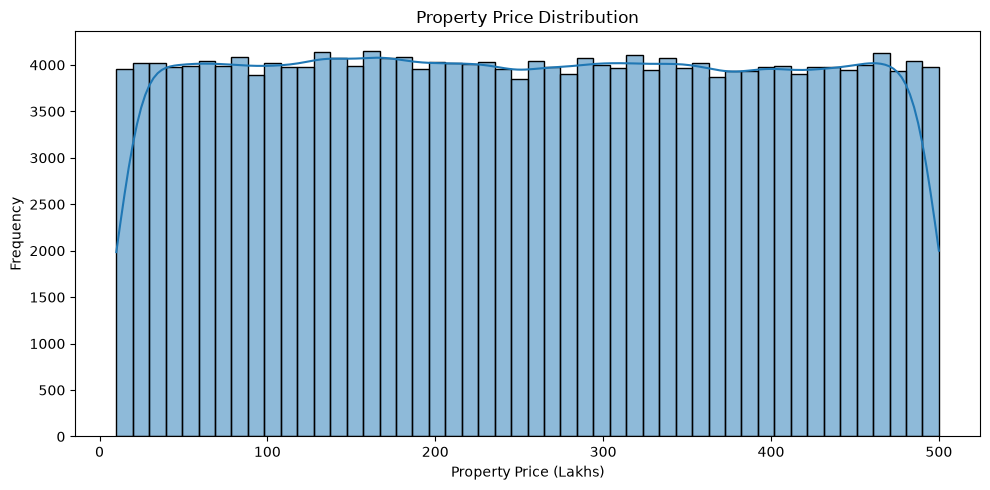

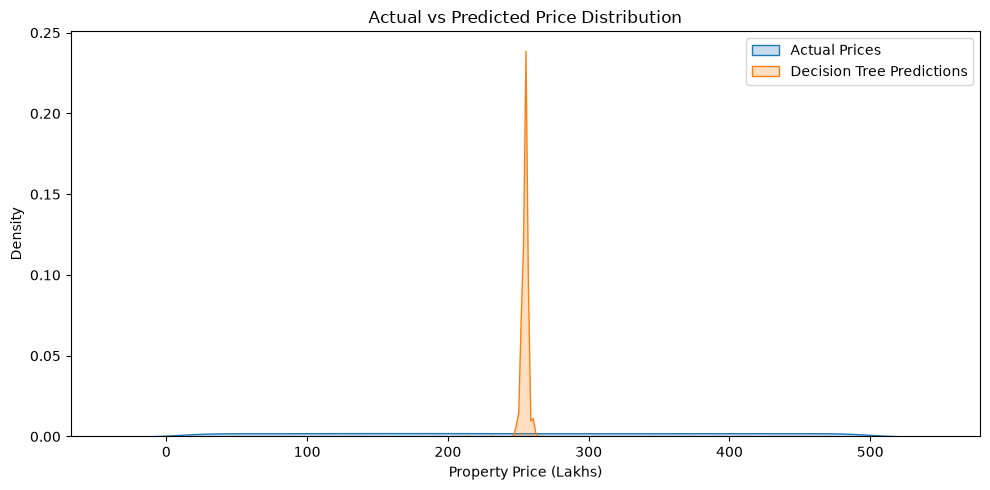


4. DECISION TREE TRAINING VS TESTING


,Dataset,MAE,MSE,RMSE,R2_Score
0,Training,122.0853,19898.5763,141.0623,0.0046
1,Testing,122.5316,20028.5423,141.5222,-0.0047



5. TARGET VARIANCE
Training Variance: 19990.868804683923
Testing Variance: 19935.904255806825

Target Investigation Completed.


In [55]:

# ==========================================
# STEP 8: TARGET VARIABLE INVESTIGATION
# ==========================================

print("=" * 55)
print("TARGET VARIABLE INVESTIGATION")
print("=" * 55)

# 1. Target distribution
print("\n1. TARGET STATISTICS")

display(y_train.describe().to_frame("Training Target"))

print("\nTesting Target Statistics")

display(y_test.describe().to_frame("Testing Target"))

# 2. Target distribution visualization
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.histplot(
    y_train,
    bins=50,
    kde=True
)

plt.title("Property Price Distribution")
plt.xlabel("Property Price (Lakhs)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

# 3. Actual vs predicted distribution
plt.figure(figsize=(10, 5))

sns.kdeplot(
    y_test,
    label="Actual Prices",
    fill=True
)

sns.kdeplot(
    dt_test_pred,
    label="Decision Tree Predictions",
    fill=True
)

plt.title("Actual vs Predicted Price Distribution")
plt.xlabel("Property Price (Lakhs)")
plt.legend()

plt.tight_layout()
plt.show()

# 4. Training vs testing performance
print("\n4. DECISION TREE TRAINING VS TESTING")

display(
    pd.DataFrame([
        {
            "Dataset": "Training",
            **dt_train_results
        },
        {
            "Dataset": "Testing",
            **dt_test_results
        }
    ]).round(4)
)

# 5. Target variance
print("\n5. TARGET VARIANCE")

print("Training Variance:", y_train.var())
print("Testing Variance:", y_test.var())

print("\nTarget Investigation Completed.")


In [56]:

# ==========================================
# STEP 9: FEATURE-TARGET RELATIONSHIP
# ==========================================

import pandas as pd
import numpy as np

print("=" * 60)
print("FEATURE-TARGET RELATIONSHIP INVESTIGATION")
print("=" * 60)

# ------------------------------------------
# 1. NUMERICAL FEATURE CORRELATION
# ------------------------------------------

numeric_corr = X_train.select_dtypes(
    include="number"
).corrwith(y_train)

numeric_corr_report = (
    numeric_corr
    .to_frame("Target_Correlation")
    .assign(
        Absolute_Correlation=lambda x:
        x["Target_Correlation"].abs()
    )
    .sort_values(
        "Absolute_Correlation",
        ascending=False
    )
)

print("\n1. NUMERICAL FEATURE CORRELATION")

display(numeric_corr_report.round(5))

# ------------------------------------------
# 2. CATEGORICAL FEATURE RELATIONSHIP
# ------------------------------------------

categorical_features = X_train.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

categorical_results = []

for feature in categorical_features:

    temp = pd.DataFrame({
        "Feature": X_train[feature],
        "Target": y_train
    })

    grouped = temp.groupby(
        "Feature",
        observed=True
    )["Target"]

    group_means = grouped.mean()

    overall_mean = y_train.mean()

    between_variance = sum(
        grouped.count() *
        (group_means - overall_mean) ** 2
    )

    total_variance = (
        ((y_train - overall_mean) ** 2).sum()
    )

    eta_squared = between_variance / total_variance

    categorical_results.append({
        "Feature": feature,
        "Unique_Values": X_train[feature].nunique(),
        "Eta_Squared": eta_squared
    })

categorical_report = pd.DataFrame(
    categorical_results
).sort_values(
    "Eta_Squared",
    ascending=False
)

print("\n2. CATEGORICAL FEATURE RELATIONSHIP")

display(categorical_report.round(6))

# ------------------------------------------
# 3. TOP FEATURE INVESTIGATION
# ------------------------------------------

print("\n3. STRONGEST NUMERICAL RELATIONSHIPS")

display(
    numeric_corr_report.head(10)
)

print("\n4. STRONGEST CATEGORICAL RELATIONSHIPS")

display(
    categorical_report.head(10)
)

print("\nFeature-target investigation completed.")


FEATURE-TARGET RELATIONSHIP INVESTIGATION

1. NUMERICAL FEATURE CORRELATION


,Target_Correlation,Absolute_Correlation
Security,0.00349,0.00349
Has_Pool,0.00235,0.00235
Year_Built,0.00225,0.00225
Nearby_Hospitals,-0.00211,0.00211
Has_Gym,0.00202,0.00202
Has_Garden,0.00152,0.00152
Has_Playground,-0.00151,0.00151
Size_in_SqFt,-0.00143,0.00143
Parking_Space,0.00125,0.00125
Has_Clubhouse,0.00118,0.00118



2. CATEGORICAL FEATURE RELATIONSHIP


,Feature,Unique_Values,Eta_Squared
2,Locality,500,0.002455
1,City,42,0.000202
0,State,20,0.000093
3,Property_Type,3,0.000037
5,Public_Transport_Accessibility,3,0.000011
8,Availability_Status,2,0.000010
7,Owner_Type,3,0.000008
6,Facing,4,0.000006
4,Furnished_Status,3,0.000003



3. STRONGEST NUMERICAL RELATIONSHIPS


,Target_Correlation,Absolute_Correlation
Security,0.003487,0.003487
Has_Pool,0.002350,0.002350
Year_Built,0.002251,0.002251
Nearby_Hospitals,-0.002107,0.002107
Has_Gym,0.002015,0.002015
Has_Garden,0.001515,0.001515
Has_Playground,-0.001506,0.001506
Size_in_SqFt,-0.001429,0.001429
Parking_Space,0.001246,0.001246
Has_Clubhouse,0.001178,0.001178



4. STRONGEST CATEGORICAL RELATIONSHIPS


,Feature,Unique_Values,Eta_Squared
2,Locality,500,0.002455
1,City,42,0.000202
0,State,20,0.000093
3,Property_Type,3,0.000037
5,Public_Transport_Accessibility,3,0.000011
8,Availability_Status,2,0.000010
7,Owner_Type,3,0.000008
6,Facing,4,0.000006
4,Furnished_Status,3,0.000003



Feature-target investigation completed.


In [57]:

# ==========================================
# STEP 10: ORIGINAL PRICE FEATURE LEAKAGE
# VERIFICATION
# ==========================================

print("=" * 60)
print("ORIGINAL PRICE FEATURE LEAKAGE INVESTIGATION")
print("=" * 60)

# Recalculate expected value from target
expected_price_sqft = (
    df["Price_in_Lakhs"] /
    df["Size_in_SqFt"]
).round(2)

original_price_sqft = (
    df["Price_per_SqFt_Original_Lakhs"]
)

# Compare values
matching_records = (
    expected_price_sqft == original_price_sqft
)

matching_percentage = matching_records.mean() * 100

print("\n1. FORMULA VERIFICATION")

print("Total Records:", len(df))

print("Matching Records:", matching_records.sum())

print("Non-Matching Records:", (~matching_records).sum())

print(
    "Matching Percentage:",
    round(matching_percentage, 4),
    "%"
)

# Calculate differences
difference = (
    original_price_sqft - expected_price_sqft
).abs()

print("\n2. DIFFERENCE STATISTICS")

display(difference.describe())

# Show sample comparison
comparison = pd.DataFrame({
    "Actual_Price": df["Price_in_Lakhs"],
    "Property_Size": df["Size_in_SqFt"],
    "Original_Price_SqFt": original_price_sqft,
    "Recalculated_Price_SqFt": expected_price_sqft,
    "Difference": difference
})

print("\n3. SAMPLE COMPARISON")

display(comparison.head(20))

# Check zero flag consistency
if "Original_Price_per_SqFt_Was_Zero" in df.columns:

    expected_zero_flag = (
        original_price_sqft == 0
    ).astype(int)

    actual_zero_flag = (
        df["Original_Price_per_SqFt_Was_Zero"]
    )

    print("\n4. ZERO FLAG VALIDATION")

    print(
        "Zero flag mismatches:",
        (expected_zero_flag != actual_zero_flag).sum()
    )

print("\nLeakage investigation completed.")


ORIGINAL PRICE FEATURE LEAKAGE INVESTIGATION

1. FORMULA VERIFICATION
Total Records: 250000
Matching Records: 249979
Non-Matching Records: 21
Matching Percentage: 99.9916 %

2. DIFFERENCE STATISTICS


count    2.500000e+05
mean     8.400000e-07
std      9.164785e-05
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      1.000000e-02
dtype: float64


3. SAMPLE COMPARISON


,Actual_Price,Property_Size,Original_Price_SqFt,Recalculated_Price_SqFt,Difference
0,489.76,4740,0.10,0.10,0.0
1,195.52,2364,0.08,0.08,0.0
2,183.79,3642,0.05,0.05,0.0
3,300.29,2741,0.11,0.11,0.0
4,182.90,4823,0.04,0.04,0.0
5,135.28,3500,0.04,0.04,0.0
6,318.12,4826,0.07,0.07,0.0
7,141.39,4252,0.03,0.03,0.0
8,189.16,2678,0.07,0.07,0.0
9,187.42,1393,0.13,0.13,0.0



4. ZERO FLAG VALIDATION
Zero flag mismatches: 0

Leakage investigation completed.


In [61]:

# ==========================================
# STEP 11: RANDOM FOREST REGRESSION
# ==========================================

from sklearn.ensemble import RandomForestRegressor
import time
import numpy as np
import pandas as pd

# Initialize model
random_forest_model = RandomForestRegressor(
    n_estimators=40,
    max_depth=12,
    min_samples_split=20,
    min_samples_leaf=10,
    max_features=0.7,
    random_state=42,
    n_jobs=2
)

# Train model
start_time = time.time()

random_forest_model.fit(
    X_train_processed,
    y_train
)

random_forest_training_time = time.time() - start_time

# Generate predictions
rf_train_pred = random_forest_model.predict(
    X_train_processed
)

rf_test_pred = random_forest_model.predict(
    X_test_processed
)

# Evaluate training performance
rf_train_results = evaluate_regression(
    y_train,
    rf_train_pred
)

# Evaluate testing performance
rf_test_results = evaluate_regression(
    y_test,
    rf_test_pred
)

# Performance comparison
random_forest_results = pd.DataFrame([
    {
        "Model": "Dummy Regressor",
        **dummy_test_results
    },
    {
        "Model": "Linear Regression",
        **test_results
    },
    {
        "Model": "Ridge Regression",
        **ridge_test_results
    },
    {
        "Model": "Lasso Regression",
        **lasso_test_results
    },
    {
        "Model": "Decision Tree",
        **dt_test_results
    },
    {
        "Model": "Random Forest",
        **rf_test_results
    }
])

print("=" * 60)
print("RANDOM FOREST REGRESSION PERFORMANCE")
print("=" * 60)

display(random_forest_results.round(4))

print("\nTraining Time:",
      round(random_forest_training_time, 2), "seconds")

print("\nNumber of Trees:",
      len(random_forest_model.estimators_))

print("\nTraining R2:",
      round(rf_train_results["R2_Score"], 4))

print("\nTesting R2:",
      round(rf_test_results["R2_Score"], 4))


RANDOM FOREST REGRESSION PERFORMANCE


,Model,MAE,MSE,RMSE,R2_Score
0,Dummy Regressor,122.3178,19935.5310,141.1932,-0.0000
1,Linear Regression,122.3571,19979.8541,141.3501,-0.0022
2,Ridge Regression,122.3568,19979.6215,141.3493,-0.0022
3,Lasso Regression,122.3162,19935.0620,141.1916,0.0000
4,Decision Tree,122.5316,20028.5423,141.5222,-0.0047
5,Random Forest,122.3419,19945.4847,141.2285,-0.0005



Training Time: 49.89 seconds

Number of Trees: 40

Training R2: 0.0086

Testing R2: -0.0005


In [62]:

# ==========================================
# STEP 12: EXTRA TREES REGRESSION
# ==========================================

from sklearn.ensemble import ExtraTreesRegressor
import time

# Initialize model
extra_trees_model = ExtraTreesRegressor(
    n_estimators=40,
    max_depth=12,
    min_samples_split=20,
    min_samples_leaf=10,
    max_features=0.7,
    random_state=42,
    n_jobs=2
)

# Training
start_time = time.time()

extra_trees_model.fit(
    X_train_processed,
    y_train
)

extra_trees_training_time = time.time() - start_time

# Predictions
et_train_pred = extra_trees_model.predict(
    X_train_processed
)

et_test_pred = extra_trees_model.predict(
    X_test_processed
)

# Evaluation
et_train_results = evaluate_regression(
    y_train,
    et_train_pred
)

et_test_results = evaluate_regression(
    y_test,
    et_test_pred
)

# Comparison
extra_trees_results = pd.DataFrame([
    {"Model": "Dummy Regressor", **dummy_test_results},
    {"Model": "Linear Regression", **test_results},
    {"Model": "Ridge Regression", **ridge_test_results},
    {"Model": "Lasso Regression", **lasso_test_results},
    {"Model": "Decision Tree", **dt_test_results},
    {"Model": "Random Forest", **rf_test_results},
    {"Model": "Extra Trees", **et_test_results}
])

print("=" * 60)
print("EXTRA TREES REGRESSION PERFORMANCE")
print("=" * 60)

display(extra_trees_results.round(4))

print("\nTraining Time:",
      round(extra_trees_training_time, 2), "seconds")

print("\nTraining R2:",
      round(et_train_results["R2_Score"], 4))

print("\nTesting R2:",
      round(et_test_results["R2_Score"], 4))


EXTRA TREES REGRESSION PERFORMANCE


,Model,MAE,MSE,RMSE,R2_Score
0,Dummy Regressor,122.3178,19935.5310,141.1932,-0.0000
1,Linear Regression,122.3571,19979.8541,141.3501,-0.0022
2,Ridge Regression,122.3568,19979.6215,141.3493,-0.0022
3,Lasso Regression,122.3162,19935.0620,141.1916,0.0000
4,Decision Tree,122.5316,20028.5423,141.5222,-0.0047
5,Random Forest,122.3419,19945.4847,141.2285,-0.0005
6,Extra Trees,122.4125,19974.8976,141.3326,-0.0020



Training Time: 43.81 seconds

Training R2: 0.0059

Testing R2: -0.002


In [63]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import time

# Train Gradient Boosting
gb_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=3,
    min_samples_split=20,
    min_samples_leaf=10,
    subsample=0.8,
    random_state=42
)

start_time = time.time()

gb_model.fit(X_train_processed, y_train)

training_time = time.time() - start_time

# Predictions
gb_train_pred = gb_model.predict(X_train_processed)
gb_test_pred = gb_model.predict(X_test_processed)

# Evaluation
gb_train_results = evaluate_regression(y_train, gb_train_pred)
gb_test_results = evaluate_regression(y_test, gb_test_pred)

print("=" * 65)
print("GRADIENT BOOSTING REGRESSION PERFORMANCE")
print("=" * 65)

print("\nTraining Performance:")
print(gb_train_results)

print("\nTesting Performance:")
print(gb_test_results)

print(f"\nTraining Time: {training_time:.2f} seconds")

GRADIENT BOOSTING REGRESSION PERFORMANCE

Training Performance:
{'MAE': 122.34644165133871, 'MSE': 19952.06328997926, 'RMSE': np.float64(141.25177269676746), 'R2_Score': 0.0019361716725557754}

Testing Performance:
{'MAE': 122.30631927920317, 'MSE': 19934.81893007591, 'RMSE': np.float64(141.19071828585587), 'R2_Score': 3.4441446418398414e-05}

Training Time: 52.99 seconds


In [64]:
import pandas as pd
import numpy as np

# Combine training features and target for investigation
diagnostic_df = X_train.copy()
diagnostic_df["Price_in_Lakhs"] = y_train

# 1. Target distribution
print("TARGET DISTRIBUTION")
display(diagnostic_df["Price_in_Lakhs"].describe())

# 2. Price relationship with property size
print("\nPRICE VS PROPERTY SIZE")
display(
    diagnostic_df.groupby(
        pd.qcut(diagnostic_df["Size_in_SqFt"], q=10, duplicates="drop")
    )["Price_in_Lakhs"].agg(
        ["count", "mean", "median", "std"]
    ).round(3)
)

# 3. Price by property type
print("\nPRICE BY PROPERTY TYPE")
display(
    diagnostic_df.groupby("Property_Type")["Price_in_Lakhs"]
    .agg(["count", "mean", "median", "std"])
    .round(3)
)

# 4. Price by state
print("\nPRICE BY STATE")
display(
    diagnostic_df.groupby("State")["Price_in_Lakhs"]
    .agg(["count", "mean", "median", "std"])
    .sort_values("mean", ascending=False)
    .round(3)
)

TARGET DISTRIBUTION


count    200000.000000
mean        254.554916
std         141.389069
min          10.000000
25%         132.460000
50%         254.145000
75%         376.760000
max         500.000000
Name: Price_in_Lakhs, dtype: float64


PRICE VS PROPERTY SIZE


,count,mean,median,std
Size_in_SqFt,,,,
"(499.999, 947.0]",20021,255.692,257.300,141.062
"(947.0, 1398.0]",20000,255.639,255.120,141.620
"(1398.0, 1847.0]",20023,254.059,254.760,141.701
"(1847.0, 2297.0]",19977,254.016,253.750,141.748
"(2297.0, 2744.0]",20001,253.918,253.750,141.172
"(2744.0, 3199.0]",19985,253.771,253.650,141.283
"(3199.0, 3648.0]",20021,254.230,251.310,141.286
"(3648.0, 4100.0]",19985,254.442,253.080,140.868
"(4100.0, 4555.0]",20024,255.413,254.605,141.654



PRICE BY PROPERTY TYPE


,count,mean,median,std
Property_Type,,,,
Apartment,66252,254.596,254.265,141.625
Independent House,66693,255.590,255.900,141.256
Villa,67055,253.485,252.200,141.282



PRICE BY STATE


,count,mean,median,std
State,,,,
Karnataka,9951,257.732,259.290,141.209
Tamil Nadu,10112,256.820,257.745,140.711
Gujarat,10150,255.948,256.670,142.062
Madhya Pradesh,9973,255.724,255.730,141.560
Uttar Pradesh,9951,255.559,257.090,141.703
Maharashtra,10081,254.889,255.550,140.577
Haryana,9876,254.815,255.125,141.253
Andhra Pradesh,9921,254.685,255.060,142.166
Jharkhand,10029,254.646,253.610,142.310


In [65]:
from scipy.stats import pearsonr, f_oneway
import pandas as pd
import numpy as np

# 1. Numerical feature relationships
numerical_test = []

for col in numerical_features:
    r, p_value = pearsonr(
        diagnostic_df[col],
        diagnostic_df["Price_in_Lakhs"]
    )

    numerical_test.append({
        "Feature": col,
        "Correlation": r,
        "P_Value": p_value
    })

numerical_results = pd.DataFrame(numerical_test)

numerical_results["Abs_Correlation"] = (
    numerical_results["Correlation"].abs()
)

numerical_results = numerical_results.sort_values(
    "Abs_Correlation",
    ascending=False
)

print("NUMERICAL FEATURE SIGNIFICANCE")
display(numerical_results.round(6))


# 2. Categorical feature relationships using ANOVA
categorical_test = []

for col in categorical_features:
    groups = [
        group["Price_in_Lakhs"].values
        for _, group in diagnostic_df.groupby(col)
    ]

    f_stat, p_value = f_oneway(*groups)

    categorical_test.append({
        "Feature": col,
        "Categories": diagnostic_df[col].nunique(),
        "F_Statistic": f_stat,
        "P_Value": p_value
    })

categorical_results = pd.DataFrame(categorical_test)

print("\nCATEGORICAL FEATURE SIGNIFICANCE")
display(
    categorical_results.sort_values(
        "F_Statistic",
        ascending=False
    ).round(6)
)

NUMERICAL FEATURE SIGNIFICANCE


,Feature,Correlation,P_Value,Abs_Correlation
6,Security,0.003487,0.118922,0.003487
7,Has_Pool,0.002350,0.293269,0.002350
2,Year_Built,0.002251,0.314105,0.002251
4,Nearby_Hospitals,-0.002107,0.346085,0.002107
10,Has_Gym,0.002015,0.367476,0.002015
9,Has_Garden,0.001515,0.498038,0.001515
11,Has_Playground,-0.001506,0.500681,0.001506
1,Size_in_SqFt,-0.001429,0.522687,0.001429
5,Parking_Space,0.001246,0.577235,0.001246
8,Has_Clubhouse,0.001178,0.598378,0.001178



CATEGORICAL FEATURE SIGNIFICANCE


,Feature,Categories,F_Statistic,P_Value
3,Property_Type,3,3.708942,0.024505
8,Availability_Status,2,2.077855,0.149452
5,Public_Transport_Accessibility,3,1.051179,0.349527
1,City,42,0.986394,0.495257
2,Locality,500,0.984056,0.591666
0,State,20,0.981395,0.479720
7,Owner_Type,3,0.750768,0.472005
6,Facing,4,0.378450,0.768548
4,Furnished_Status,3,0.301079,0.740019


In [66]:
# Inspect the original, unmodified dataset

print("DATASET SHAPE:")
print(df.shape)

print("\nALL ORIGINAL COLUMNS:")
for i, col in enumerate(df.columns, start=1):
    print(f"{i}. {col}")

print("\nTARGET-RELATED COLUMNS:")
target_related = [
    col for col in df.columns
    if any(word in col.lower() for word in [
        "price", "investment", "return",
        "rent", "yield", "profit", "appreciation"
    ])
]

print(target_related)

print("\nSAMPLE RECORDS:")
display(df.head(10))

print("\nTARGET UNIQUE VALUES:")
print("Unique count:", df["Price_in_Lakhs"].nunique())
print("Sample values:", sorted(df["Price_in_Lakhs"].sample(
    min(20, len(df)),
    random_state=42
).tolist()))

DATASET SHAPE:
(250000, 37)

ALL ORIGINAL COLUMNS:
1. ID
2. State
3. City
4. Locality
5. Property_Type
6. BHK
7. Size_in_SqFt
8. Price_in_Lakhs
9. Price_per_SqFt_Original_Lakhs
10. Year_Built
11. Furnished_Status
12. Floor_No
13. Total_Floors
14. Age_of_Property
15. Nearby_Schools
16. Nearby_Hospitals
17. Public_Transport_Accessibility
18. Parking_Space
19. Security
20. Amenities
21. Facing
22. Owner_Type
23. Availability_Status
24. Price_per_SqFt
25. Has_Pool
26. Has_Clubhouse
27. Has_Garden
28. Has_Gym
29. Has_Playground
30. Original_Price_per_SqFt_Was_Zero
31. Calculated_Price_per_SqFt
32. Price_SqFt_Difference
33. Implied_Price
34. Implied_Price_Difference
35. Calculated_Age
36. Floor_Status
37. Floor_Difference

TARGET-RELATED COLUMNS:
['Price_in_Lakhs', 'Price_per_SqFt_Original_Lakhs', 'Price_per_SqFt', 'Original_Price_per_SqFt_Was_Zero', 'Calculated_Price_per_SqFt', 'Price_SqFt_Difference', 'Implied_Price', 'Implied_Price_Difference']

SAMPLE RECORDS:


,ID,State,City,Locality,Property_Type,BHK,Size_in_SqFt,Price_in_Lakhs,Price_per_SqFt_Original_Lakhs,Year_Built,...,Has_Gym,Has_Playground,Original_Price_per_SqFt_Was_Zero,Calculated_Price_per_SqFt,Price_SqFt_Difference,Implied_Price,Implied_Price_Difference,Calculated_Age,Floor_Status,Floor_Difference
0,1,Tamil Nadu,Chennai,Locality_84,Apartment,1,4740,489.76,0.10,1990,...,1,1,0,10332.489451,0.0,474.00,15.76,35,Invalid,21
1,2,Maharashtra,Pune,Locality_490,Independent House,3,2364,195.52,0.08,2008,...,1,1,0,8270.727580,0.0,189.12,6.40,17,Invalid,1
2,3,Punjab,Ludhiana,Locality_167,Apartment,2,3642,183.79,0.05,1997,...,1,1,0,5046.403075,0.0,182.10,1.69,28,Valid,-8
3,4,Rajasthan,Jodhpur,Locality_393,Independent House,2,2741,300.29,0.11,1991,...,1,1,0,10955.490697,0.0,301.51,1.22,34,Valid,-5
4,5,Rajasthan,Jaipur,Locality_466,Villa,4,4823,182.90,0.04,2002,...,1,1,0,3792.245490,0.0,192.92,10.02,23,Invalid,1
5,6,West Bengal,Durgapur,Locality_246,Apartment,4,3500,135.28,0.04,2020,...,0,1,0,3865.142857,0.0,140.00,4.72,5,Invalid,26
6,7,Tamil Nadu,Coimbatore,Locality_254,Independent House,3,4826,318.12,0.07,2016,...,0,1,0,6591.794447,0.0,337.82,19.70,9,Invalid,11
7,8,Chhattisgarh,Bilaspur,Locality_490,Independent House,5,4252,141.39,0.03,2021,...,1,1,0,3325.258702,0.0,127.56,13.83,4,Invalid,20
8,9,Delhi,New Delhi,Locality_232,Villa,4,2678,189.16,0.07,2003,...,0,1,0,7063.480209,0.0,187.46,1.70,22,Invalid,7
9,10,Jharkhand,Ranchi,Locality_122,Villa,2,1393,187.42,0.13,2011,...,1,1,0,13454.414932,0.0,181.09,6.33,14,Valid,-7



TARGET UNIQUE VALUES:
Unique count: 48700
Sample values: [35.17, 55.67, 86.04, 124.99, 188.68, 208.0, 232.85, 237.86, 251.02, 256.17, 256.62, 275.75, 282.46, 297.51, 339.41, 355.61, 374.76, 418.06, 425.27, 476.35]


In [67]:
import numpy as np
import pandas as pd

# Inspect price distribution in the original dataset
price = df["Price_in_Lakhs"]

print("PRICE GENERATION INVESTIGATION")
print("-" * 50)

print("Minimum:", price.min())
print("Maximum:", price.max())
print("Mean:", price.mean())
print("Median:", price.median())
print("Standard deviation:", price.std())

print("\nRounded decimal distribution:")
print(price.round(2).value_counts().head(15))

print("\nPrice interval frequencies:")
print(
    pd.cut(price, bins=10)
    .value_counts()
    .sort_index()
)

PRICE GENERATION INVESTIGATION
--------------------------------------------------
Minimum: 10.0
Maximum: 500.0
Mean: 254.58685404
Median: 253.87
Standard deviation: 141.349921072615

Rounded decimal distribution:
Price_in_Lakhs
42.76     16
316.07    16
292.91    16
423.58    16
40.22     16
137.92    16
454.02    15
497.89    15
372.93    15
228.84    15
82.79     15
144.40    15
362.47    15
229.15    15
106.74    15
Name: count, dtype: int64

Price interval frequencies:
Price_in_Lakhs
(9.51, 59.0]      24894
(59.0, 108.0]     24952
(108.0, 157.0]    25299
(157.0, 206.0]    25465
(206.0, 255.0]    24945
(255.0, 304.0]    24900
(304.0, 353.0]    24943
(353.0, 402.0]    24725
(402.0, 451.0]    24789
(451.0, 500.0]    25088
Name: count, dtype: int64
